Fie setul de date German Traffic Sign Recognition Benchmark (GTSRB), ce conține imagini color reprezentând indicatoare rutiere, sub diferite condiții de iluminare, stare meteorologică, sau poziție.

Afișați aleator o serie de eșantioane din setul de date, respectiv eticheta asociată.

Ce puteți spune cu privire la rezoluția imaginilor?

In [ ]:
!pip install gdown -q
import gdown, zipfile, os

os.makedirs("./data/gtsrb", exist_ok=True)
gdown.download(id="1lyDmUg4ZnGfgIE4bQypB5liQcpM2vvft", output="gtsrb.zip", quiet=False)

with zipfile.ZipFile("gtsrb.zip", "r") as zf:
    zf.extractall("./data/gtsrb")


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchsummary import summary

gtsrb_train = datasets.GTSRB(root="./data", split="train", download=False)
gtsrb_test = datasets.GTSRB(root="./data", split="test", download=False)
n_samples = 10
for i in range(n_samples):
    # Selectați o imagine și verificați rezoluția & clasa
    idx = np.random.randint(...)
    img, label = gtsrb_train[idx]

    plt.imshow(img)
    plt.show()
    print(label)


Afișați distribuția claselor în setul vostru de date (atât antrenare, cât și testare).

Câte clase distincte există în setul de date?

Ce puteți spune despre cele două distribuții?

**Sugestie**: puteți utiliza funcția *unique* implementată în biblioteca *numpy*.

In [ ]:
train_labels = np.unique([
    ...
    ], return_counts=True
)
test_labels = np.unique([
    ...
    ], return_counts=True
)

print(np.max(train_labels[0]))

fig, axs = plt.subplots(1, 2, figsize=(15, 4))

axs[0].set_title("Distribuția datelor de antrenare")
axs[0].bar(train_labels[0], train_labels[1])

axs[1].set_title("Distribuția datelor de test")
axs[1].bar(test_labels[0], test_labels[1])

for ax in axs:
    ax.set_xlabel("Clasa")
    ax.set_ylabel('Numar exemple')

plt.show()

Completați definiția instanței transform astfel încât să realizeze redimensionarea fiecărei imagini din setul de date la o rezoluție standard aleasă de dvs. (ex. 48 x 48 pixeli), să realizeze scalarea imaginii în intervalul [0, 1], respectiv să transforme imaginile în torch.FloatTensor. Iterați prin noul set de date și verificați efectul transformării.

**Sugestie**: consultați documentația modulului *transforms*.

In [ ]:
transform = transforms.Compose([
    ...
])

gtsrb_train = datasets.GTSRB(root="./data", split="train", download=True, transform=transform)
gtsrb_test = datasets.GTSRB(root="./data", split="test", download=True, transform=transform)

n_samples = 10
for i in range(n_samples):
    # Selectați o imagine și verificați rezoluția & clasa
    idx = np.random.randint(...)
    img = ...
    label = ...

    plt.imshow(img)
    plt.show()
    print(label)

train_loader = torch.utils.data.DataLoader(gtsrb_train, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(gtsrb_test, batch_size=32, shuffle=False)

for x, y in train_loader:
    print(x.shape, y.shape)
    break

Implementați o rețea convoluțională simplă conform Fig. 1, apoi afișați structura detaliată utilizând funcția summary din biblioteca torchsummary :

1.   Rețeaua trebuie să conțină doar straturi convoluționale 2D (nn.Conv2d), straturi de agregare (ex. nn.MaxPool2d, nn.AvgPool2d), activare (ex. F.relu, F.leaky_relu_, F.sigmoid, etc sau nn.ReLU, nn.Sigmoid, etc) respectiv staturi complet conectate (nn.Linear).
2.   Rețeaua trebuie să conțină cel puțin 3 straturi convoluționale, respectiv cel puțin 1 strat complet conectat.
3.   Intrarea rețelei este un tensor de dimensiunea (B, C, H, W), unde B reprezintă dimensiunea batch-ului, C reprezintă dimensiunea canalelor de culoare, iar H și W reprezintă dimensiunile imaginii.
4.   Ieșirea rețelei este un tensor de dimensiune (B, n_classes) unde B este dimensiunea batch-ului, iar n_classes reprezintă numărul de clase (vezi exercițiul 2).
5.   Pentru a determina dimensiunea ieșirii fiecărui strat convoluțional Conv2d, sau MaxPool2d, se poate folosi formula:
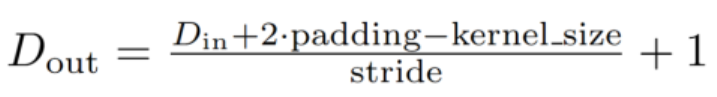


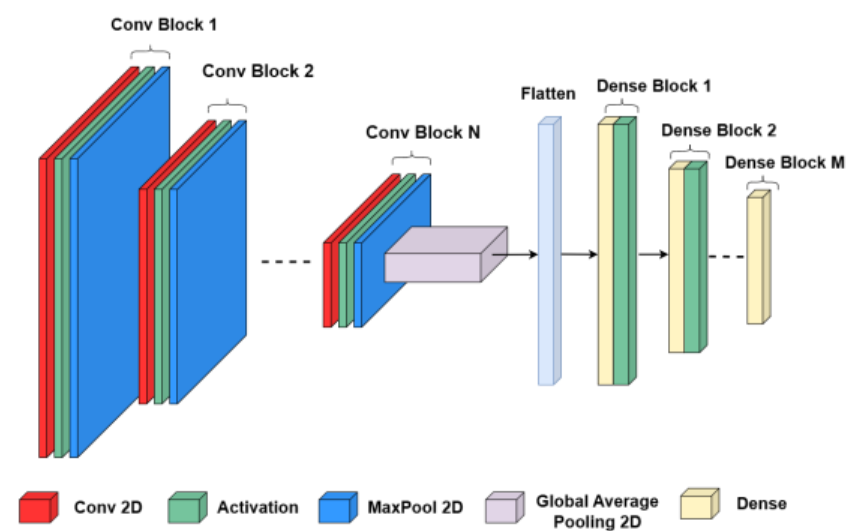

Fig.1 - Exemplificarea arhitecturii neurale convoluționale


In [ ]:
class SimpleCNN(nn.Module):
 def __init__(self):
    super(SimpleCNN, self).__init__()

    ...

 def forward(self, x):
    ...

model = SimpleCNN()
summary(model, (3, 48, 48), device="cpu")

Antrenați modelul și observați rezultatele. Cum influențează diverși hiperparametri performanța modelului (e.g. numărul de straturi convoluționale/dense, numărul de filtre convoluționale utilizate per strat, alegerea funcțiilor de activare, etc.)?

In [ ]:
def train(model, dataloader, optimizer, loss_fn, device="cuda"):
    model.train()
    total_loss, total_correct, total = 0.0, 0, 0
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        total_correct += (out.argmax(dim=-1) == y).sum().item()
        total += y.size(0)

    return total_loss / len(dataloader), total_correct / total

def test(model, dataloader, loss_fn, device="cuda"):
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            total_loss += loss.item()
            total_correct += (out.argmax(dim=-1) == y).sum().item()
            total += y.size(0)

    return total_loss / len(dataloader), total_correct / total

def plot_metrics(train_losses, test_losses, train_accs, test_accs):
    epochs = range(1, len(train_losses) + 1)
    # --- Plot Funcție Cost ---
    plt.figure(figsize=(10,4))
    plt.plot(epochs, train_losses, label='Train Loss', marker='o')
    plt.plot(epochs, test_losses, label='Test Loss', marker='o')
    plt.title('Training & Test Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.legend()
    plt.show()
    # --- Plot Acuratețe ---
    plt.figure(figsize=(10,4))
    plt.plot(epochs, train_accs, label='Train Accuracy', marker='o')
    plt.plot(epochs, test_accs, label='Test Accuracy', marker='o')
    plt.title('Training & Test Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.grid(True)
    plt.legend()
    plt.show()

def train_loop(model, train_loader, test_loader, optimizer, loss_fn, epochs, device="cuda"):
    train_losses, train_accs = [], []
    test_losses, test_accs = [], []
    best_loss = None

    for epoch in range (epochs):
        print(f"\nEpoch {epoch + 1}/{epochs}")

        # Pas de Antrenare
        train_loss, train_acc = train(model, train_loader, optimizer, loss_fn, device=device)
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        print(f" Train | Loss: {train_loss:.4f} | Accuracy: {train_acc * 100:.2f}%")

        # Pas Testare
        test_loss, test_acc = test(model, test_loader, loss_fn, device=device)
        test_losses.append(test_loss)
        test_accs.append(test_acc)
        print(f"  Test | Loss: {test_loss:.4f} | Accuracy: {test_acc * 100:.2f}%")

        # Salvarea celui mai Bun Model
        if best_loss is None or test_loss < best_loss:
            torch.save(model, 'model.pt')
            print(f"Saved new best model (test_loss={test_loss:.4f})")

    # Afișarea evoluției funcției de cost/acurateței
    plot_metrics(train_losses, test_losses, train_accs, test_accs)


optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
epochs = 10
train_loop(model, train_loader, test_loader, optimizer, loss_fn, epochs)

Adăugați straturi de normalizare a activărilor per lot (vezi nn.BatchNorm2d) și/sau straturi de regularizare (e.g. nn.Dropout) și reantrenați rețeaua. Cum este influențată performanța modelului?

Antrenați un model convoluțional de cel mult 100k parametri antrenabili, care să obțină o acuratețe de cel puțin 95% pe datele de testare.
